In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from category_encoders import TargetEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, LassoCV, Ridge, RidgeCV
from sklearn.metrics import mean_squared_error, r2_score

In [37]:
df = pd.read_csv(r"D:\머신러닝\Datasets\kc_house_data.csv\kc_house_data.csv")
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [38]:
print(df.columns)
df.info()

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  i

In [39]:
#EDA
#missing values
df.isna().sum().sum()

np.int64(0)

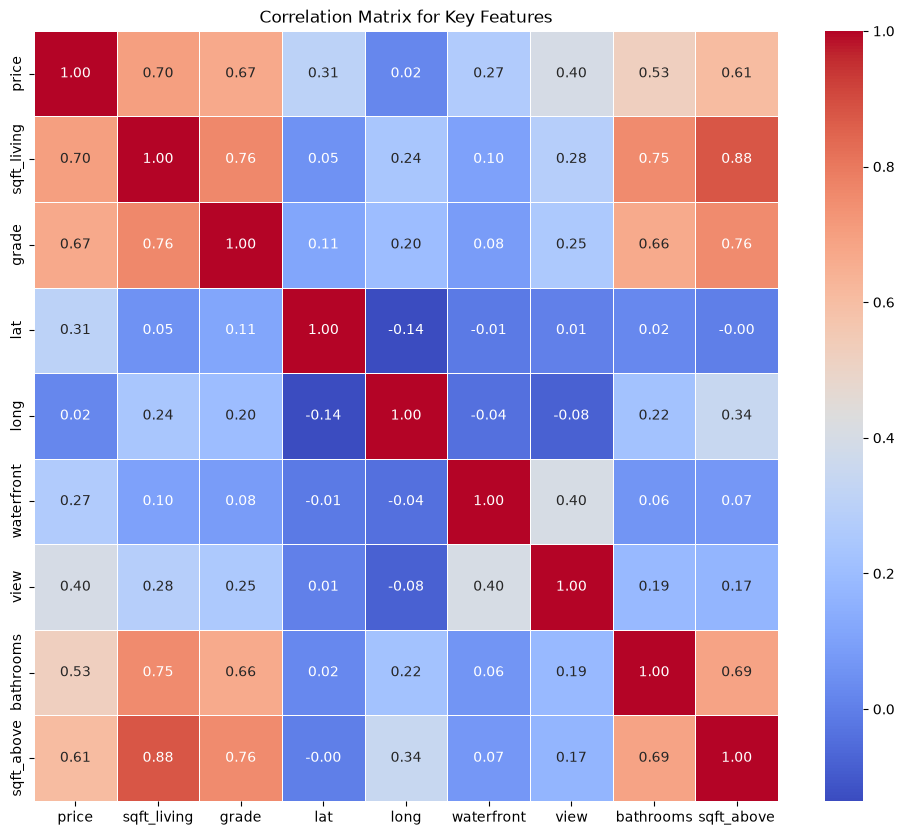

price          1.000000
sqft_living    0.702035
grade          0.667434
sqft_above     0.605567
bathrooms      0.525138
view           0.397293
lat            0.307003
waterfront     0.266369
long           0.021626
Name: price, dtype: float64


In [40]:
#Correlation Matrix
plt.figure(figsize=(12, 10))

numeric_cols=[
    'price',
    'sqft_living',
    'grade',
    'lat',
    'long',
    'waterfront',
    'view',
    'bathrooms',
    'sqft_above'
]
corr_matrix= df[numeric_cols].corr()

sns.heatmap(
    corr_matrix, annot=True, cmap='coolwarm', fmt= '.2f', linewidths=0.5)

plt.title('Correlation Matrix for Key Features')
plt.show()

print(corr_matrix['price'].sort_values(ascending=False))

Text(0.5, 1.0, 'Original sqft_living Distibution')

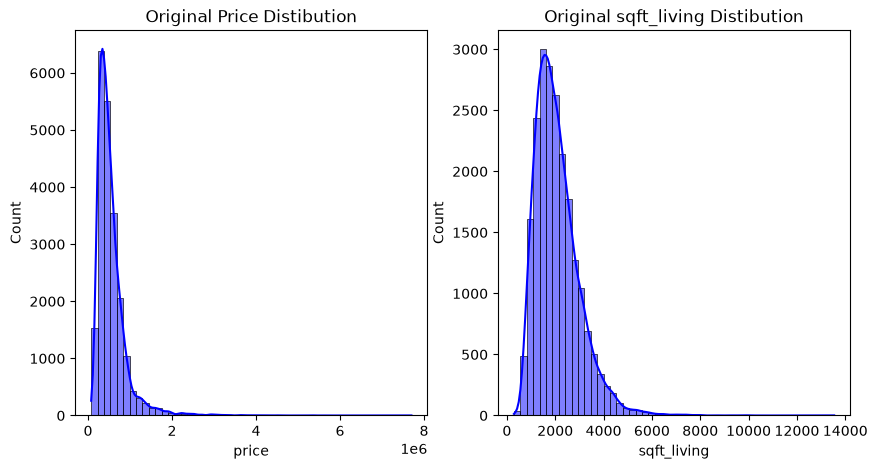

In [41]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['price'], kde=True, bins= 50, color='blue')
plt.title('Original Price Distibution')

plt.subplot(1, 2, 2)
sns.histplot(df['sqft_living'], kde=True, bins= 50, color='blue')
plt.title('Original sqft_living Distibution')



In [42]:
def remove_outliers(data, column):
    Q1= data[column].quantile(0.25)
    Q3= data[column].quantile(0.75)
    IQR= Q3- Q1

    lower_bound= Q1- 1.5* IQR
    upper_bound= Q3+ 1.5* IQR

    filtered_data= data[
        (data[column] >= lower_bound) & (data[column] <= upper_bound)
    ]
    return filtered_data

print(f'original shape: {df.shape}')

df_clean= remove_outliers(df, 'sqft_living')
df_clean= remove_outliers(df_clean, 'price')

print(f'Shape after removing outliers: {df_clean.shape}')


original shape: (21613, 21)
Shape after removing outliers: (20203, 21)


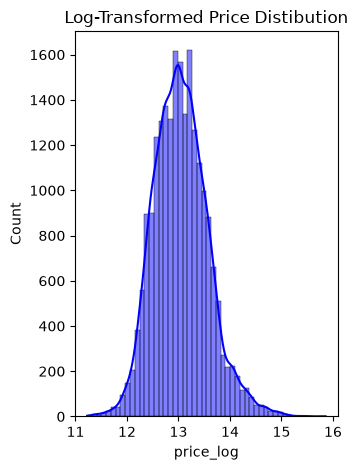

In [43]:
df['price_log']= np.log1p(df['price'])

plt.subplot(1, 2, 2)
sns.histplot(df['price_log'], kde=True, bins= 50, color='blue')
plt.title('Log-Transformed Price Distibution')

plt.tight_layout()
plt.show()

#We will use 'price_log' instead of 'price' as a target


In [44]:
#feature engineering
df['yr_sale']= df['date'].str[:4]
df['yr_sale'] = df['yr_sale'].astype(int)
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,price_log,yr_sale
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,0,1955,0,98178,47.5112,-122.257,1340,5650,12.309987,2014
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,400,1951,1991,98125,47.7210,-122.319,1690,7639,13.195616,2014
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,0,1933,0,98028,47.7379,-122.233,2720,8062,12.100718,2015
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,910,1965,0,98136,47.5208,-122.393,1360,5000,13.311331,2014
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,0,1987,0,98074,47.6168,-122.045,1800,7503,13.142168,2015


In [45]:
df['House_Age_At_Sale'] = df['yr_sale'] - df['yr_built']
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,price_log,yr_sale,House_Age_At_Sale
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,1955,0,98178,47.5112,-122.257,1340,5650,12.309987,2014,59
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,1951,1991,98125,47.7210,-122.319,1690,7639,13.195616,2014,63
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,1933,0,98028,47.7379,-122.233,2720,8062,12.100718,2015,82
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,1965,0,98136,47.5208,-122.393,1360,5000,13.311331,2014,49
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,1987,0,98074,47.6168,-122.045,1800,7503,13.142168,2015,28


In [46]:
X= df.drop(columns=['price', 'id', 'date', 'price_log'])
y= df['price_log']

In [47]:
X_train, X_test, y_train, y_test= train_test_split(
    X, y, test_size=0.2, random_state=42)

X_train['zipcode']= X_train['zipcode'].astype(str)
X_test['zipcode']= X_test['zipcode'].astype(str)

encoder= TargetEncoder(cols=['zipcode'])

X_train_encoded = encoder.fit_transform(X_train, y_train)
X_test_encoded = encoder.transform(X_test)

print(X_train_encoded[['zipcode', 'lat', 'long']].head())

         zipcode      lat     long
6325   12.602890  47.3670 -122.152
13473  12.825936  47.5520 -122.290
17614  12.643863  47.4838 -122.335
16970  12.587613  47.3951 -122.172
20868  13.072519  47.7043 -122.209


In [48]:
scaler= StandardScaler()
X_train_scaled= scaler.fit_transform(X_train_encoded)
X_test_scaled= scaler.fit_transform(X_test_encoded)

In [57]:
lr= LinearRegression()

lr.fit(X_train_scaled, y_train)
y_pred= lr.predict(X_test_encoded)

r2_lr= r2_score(y_test, y_pred)
rmse_lr= np.sqrt(mean_squared_error(y_test, y_pred))

c:\Users\powfu\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


In [58]:
#L1 Lasso Regression
lasso_cv= LassoCV(cv=5, random_state=42, max_iter=10000)
lasso_cv.fit(X_train_scaled, y_train)

print(f'Best alpha for Lasso: {lasso_cv.alpha_}')
y_pred_lasso = lasso_cv.predict(X_test_scaled)
r2_lasso = r2_score(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))

Best alpha for Lasso: 0.0012559111587473846


In [59]:
#L2 Ridge Regression

alphas= [0.1, 1.0, 10.0, 100.0, 1000.0]
ridge_cv= RidgeCV(alphas=alphas, cv=5, scoring='r2')
ridge_cv.fit(X_train_scaled, y_train)

print(f'Best Alpha for Ridge: {ridge_cv.alpha_}')

y_pred_ridge = ridge_cv.predict(X_test_scaled)
r2_ridge = r2_score(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

Best Alpha for Ridge: 100.0


In [60]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Ridge Regression',
        'Lasso Regression',
    ],
    'R2 Score': [r2_lr, r2_ridge, r2_lasso],
    'RMSE': [rmse_lr, rmse_ridge, rmse_lasso],
})

print(results)

               Model      R2 Score         RMSE
0  Linear Regression -7.440309e+06  1456.268329
1   Ridge Regression  8.575679e-01     0.201488
2   Lasso Regression  8.573483e-01     0.201644


In [64]:
lasso_coefs = pd.DataFrame(
    {'Feature': X.columns, 'Coefficient': lasso_cv.coef_}
)

print('\n--- Lasso Coefficients (Features Selected vs Dropped) ---')

dropped_features = lasso_coefs[lasso_coefs['Coefficient'] == 0]
print(f'Number of features dropped by Lasso: {len(dropped_features)}')
print(dropped_features['Feature'].values)

print('\nTop Features by Lasso Coefficients:')
print(lasso_coefs.sort_values(by='Coefficient', ascending=False).head(10))


--- Lasso Coefficients (Features Selected vs Dropped) ---
Number of features dropped by Lasso: 3
<StringArray>
['bedrooms', 'sqft_basement', 'sqft_lot15']
Length: 3, dtype: str

Top Features by Lasso Coefficients:
          Feature  Coefficient
13        zipcode     0.233245
2     sqft_living     0.127552
8           grade     0.114837
14            lat     0.058947
6            view     0.049442
1       bathrooms     0.041391
9      sqft_above     0.032119
5      waterfront     0.031874
7       condition     0.029726
16  sqft_living15     0.027024
